In [1]:
# 1. Cek GPU & Install Library timm
!nvidia-smi
!pip install -q timm


Thu Oct 15 15:04:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 🌿 Pelatihan Model ConvNeXt-Tiny: CASCADE 5-Fold Cross Validation

Dokumen notebook ini berisi pipeline pelatihan **CASCADE Two-Stage (Stage 1 Jenis & Stage 2 Sangrai)** berbasis arsitektur **ConvNeXt-Tiny** menggunakan skema **Stratified 5-Fold Cross Validation**.

### Ringkasan Alur CASCADE:
1. **Stage 1 (Model Jenis)**: 1 model pengklasifikasi 4 spesies kopi (*Arabika, Ekselsa, Liberika, Robusta*).
2. **Stage 2 (Model Sangrai)**: 4 model spesifik sangrai (*Arabika Sangrai, Ekselsa Sangrai, Liberika Sangrai, Robusta Sangrai*) masing-masing 4 kelas (*Dark, Green, Light, Medium*).
3. **Evaluasi Berantai 16 Kelas**: Prediksi spesies di tahap 1 me-routing citra ke model sangrai yang relevan di tahap 2 untuk menghasilkan prediksi akhir 16 kombinasi kelas secara end-to-end.


## 1. Import Libraries, Random Seed & Pengaturan Direktori Lingkungan


In [2]:
import os
import json
import time
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets
from torch.optim.lr_scheduler import CosineAnnealingLR

import timm
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# --- REPRODUCIBILITY SEED ---
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# --- DEVICE ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[INFO] Running on Device: {device}')
if torch.cuda.is_available():
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)}')

# --- DIREKTORI DATASET & OUTPUT DI KAGGLE ---
input_base = '/kaggle/input'
work_dir = '/kaggle/working'

# Cari letak Dataset 5-Fold di /kaggle/input secara dinamis
TARGET_SPLIT2_DIR = None
for root, dirs, files in os.walk(input_base):
    if 'fold_1' in dirs and 'fold_2' in dirs:
        TARGET_SPLIT2_DIR = root
        break

if TARGET_SPLIT2_DIR is None:
    # Cek jika dataset masih berbentuk file zip
    for root, dirs, files in os.walk(input_base):
        for f in files:
            if f.endswith('.zip'):
                zp = os.path.join(root, f)
                print(f'Mengekstrak {zp} ke {work_dir}/extracted_dataset...')
                ext_target = os.path.join(work_dir, 'extracted_dataset')
                os.makedirs(ext_target, exist_ok=True)
                with zipfile.ZipFile(zp, 'r') as zf:
                    zf.extractall(ext_target)
                break
    for root, dirs, files in os.walk(work_dir):
        if 'fold_1' in dirs and 'fold_2' in dirs:
            TARGET_SPLIT2_DIR = root
            break

MODELS_DIR = os.path.join(work_dir, 'models', 'CASCADE')
REPORTS_DIR = os.path.join(work_dir, 'reports')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

print(f'[INFO] Direktori Dataset: {TARGET_SPLIT2_DIR}')
print(f'[INFO] Simpan Model Ke  : {MODELS_DIR}')
print(f'[INFO] Simpan Report Ke : {REPORTS_DIR}')


[INFO] Running on Device: cuda
[INFO] GPU: Tesla T4
[INFO] Direktori Dataset: /kaggle/input/datasets/hhnurfathurrachman/coffee-beans-dataset-split2/Dataset_Split2
[INFO] Simpan Model Ke  : /kaggle/working/models/CASCADE
[INFO] Simpan Report Ke : /kaggle/working/reports


## 2. Pemetaan Label & Verifikasi Partisi Fold


In [3]:
# Pemetaan Label
JENIS_LABELS   = {'arabika': 0, 'ekselsa': 1, 'liberika': 2, 'robusta': 3}
SANGRAI_LABELS = {'dark': 0, 'green': 1, 'light': 2, 'medium': 3}

SPECIES_NAMES = ['Arabika', 'Ekselsa', 'Liberika', 'Robusta']
ROAST_NAMES   = ['Dark', 'Green', 'Light', 'Medium']

CLASS_NAMES_16 = [
    f"{j}_{s}" 
    for j in SPECIES_NAMES
    for s in ROAST_NAMES
]

print(f"[INFO] Status Ketersediaan Fold di: {TARGET_SPLIT2_DIR}")
if TARGET_SPLIT2_DIR:
    for fold_idx in range(1, 6):
        f_path = os.path.join(TARGET_SPLIT2_DIR, f'fold_{fold_idx}')
        tr_cnt = sum(len(files) for _, _, files in os.walk(os.path.join(f_path, 'train'))) if os.path.exists(os.path.join(f_path, 'train')) else 0
        va_cnt = sum(len(files) for _, _, files in os.walk(os.path.join(f_path, 'val'))) if os.path.exists(os.path.join(f_path, 'val')) else 0
        print(f"  Fold {fold_idx}: Train = {tr_cnt} citra | Val = {va_cnt} citra (Total = {tr_cnt + va_cnt})")


[INFO] Status Ketersediaan Fold di: /kaggle/input/datasets/hhnurfathurrachman/coffee-beans-dataset-split2/Dataset_Split2
  Fold 1: Train = 1280 citra | Val = 320 citra (Total = 1600)
  Fold 2: Train = 1280 citra | Val = 320 citra (Total = 1600)
  Fold 3: Train = 1280 citra | Val = 320 citra (Total = 1600)
  Fold 4: Train = 1280 citra | Val = 320 citra (Total = 1600)
  Fold 5: Train = 1280 citra | Val = 320 citra (Total = 1600)


## 3. Augmentasi Citra & Arsitektur ConvNeXt-Tiny


In [4]:
def get_transforms(img_size=224):
    """
    Transformasi citra dengan augmentasi terukur:
    - Rotasi 15 derajat untuk mempertahankan geometri alami biji.
    - ColorJitter halus (0.05) menjaga ketelitian warna sangrai.
    - Random Horizontal & Vertical Flip untuk variasi orientasi.
    """
    train_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.05, contrast=0.05),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    val_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    return train_tf, val_tf


def build_convnext(num_classes=4, drop_rate=0.3):
    """Membangun ConvNeXt-Tiny dengan Custom Head 768 -> 512 -> num_classes."""
    model = timm.create_model('convnext_tiny', pretrained=True, num_classes=num_classes, drop_rate=drop_rate)
    in_features = model.head.fc.in_features  # 768
    model.head.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.LayerNorm(512),
        nn.GELU(),
        nn.Dropout(drop_rate),
        nn.Linear(512, num_classes)
    )
    return model


## 4. Engine Pelatihan (2-Phase Warmup, Discriminative Learning Rate & Cosine Annealing)


In [5]:
def train_kfold_model(
    train_loader,
    val_loader,
    num_classes=4,
    save_name="model.pth",
    label_info="Fold 1",
    target_name=None,
    num_epochs=100,
    warmup_epochs=8,
    patience=15
):
    model = build_convnext(num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    display_target = target_name if target_name is not None else label_info

    # --- FASE 1: WARMUP (Freeze Backbone) ---
    for p in model.parameters():
        p.requires_grad = False
    for p in model.head.parameters():
        p.requires_grad = True

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=5e-4, weight_decay=1e-2
    )
    scheduler = None

    best_acc = 0.0
    best_val_loss = float('inf')
    patience_counter = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print(f"\n[INFO] Device: {device} | Model: ConvNeXt-Tiny | Target: {display_target}")
    print(f"{'='*65}")
    print(f"  MULAI TRAINING: {label_info} | Output: {num_classes} Kelas | Max Epoch: {num_epochs}")
    print(f"{'='*65}")

    for epoch in range(num_epochs):

        # --- FASE 2: UNFREEZE (Tuned Discriminative LR) ---
        if epoch == warmup_epochs:
            for p in model.parameters():
                p.requires_grad = True

            optimizer = optim.AdamW([
                {'params': list(model.stem.parameters()) +
                            list(model.stages[0].parameters()) +
                            list(model.stages[1].parameters()), 'lr': 1.5e-5},
                {'params': list(model.stages[2].parameters()) +
                            list(model.stages[3].parameters()), 'lr': 6e-5},
                {'params': list(model.head.parameters()),      'lr': 2.5e-4},
            ], weight_decay=1e-2)

            scheduler = CosineAnnealingLR(optimizer, T_max=(num_epochs - warmup_epochs), eta_min=1e-6)

        # Train Phase
        model.train()
        running_loss, train_correct, train_total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_loss  += loss.item() * inputs.size(0)
            _, preds       = torch.max(outputs, 1)
            train_total   += labels.size(0)
            train_correct += (preds == labels).sum().item()

        if epoch >= warmup_epochs and scheduler is not None:
            scheduler.step()

        epoch_tr_loss = running_loss / len(train_loader.dataset)
        epoch_tr_acc  = train_correct / train_total

        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, labels)

                val_loss    += loss.item() * inputs.size(0)
                _, preds     = torch.max(outputs, 1)
                val_total   += labels.size(0)
                val_correct += (preds == labels).sum().item()

        epoch_va_loss = val_loss / len(val_loader.dataset)
        epoch_va_acc  = val_correct / val_total

        history['train_loss'].append(epoch_tr_loss)
        history['train_acc'].append(epoch_tr_acc)
        history['val_loss'].append(epoch_va_loss)
        history['val_acc'].append(epoch_va_acc)

        if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"{label_info} | Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | Val Loss: {epoch_va_loss:.4f} Acc: {epoch_va_acc*100:.2f}%")

        if epoch_va_acc > best_acc:
            best_acc = epoch_va_acc
            torch.save(model.state_dict(), save_name)

        if epoch_va_loss < best_val_loss:
            best_val_loss = epoch_va_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience and epoch >= warmup_epochs + 7:
                print(f"[Early Stopping] {label_info} berhenti di epoch {epoch+1}.")
                break

    print(f"=> {label_info} Selesai! Best Val Accuracy: {best_acc*100:.2f}%")

    # --- GRAFIK HISTORY LOSS & ACCURACY ---
    epochs_range = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Train Loss')
    plt.plot(epochs_range, history['val_loss'],   label='Val Loss')
    plt.legend()
    plt.title(f'ConvNeXt-Tiny — Loss ({display_target})')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Train Acc')
    plt.plot(epochs_range, history['val_acc'],   label='Val Acc')
    plt.legend()
    plt.title(f'ConvNeXt-Tiny — Accuracy ({display_target})')
    plt.grid(True)
    plt.tight_layout()

    safe_name = label_info.replace(' ', '_').replace('/', '_')
    plot_path = f"{REPORTS_DIR}/History_{safe_name}.png"
    try:
        plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    except Exception:
        pass
    plt.show()

    return history, best_acc


## 5. Eksekusi Utama: CASCADE 5-Fold Cross Validation (Stage 1 Jenis & Stage 2 Sangrai)



         CASCADE FOLD 1 (100 EPOCHS)

[STAGE 1] Training Model Jenis (4 Spesies)...


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]


[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Jenis
  MULAI TRAINING: CASCADE Jenis Fold 1 | Output: 4 Kelas | Max Epoch: 100
CASCADE Jenis Fold 1 | Epoch 01/100 | Train Loss: 1.1751 Acc: 51.25% | Val Loss: 0.9438 Acc: 68.12%
CASCADE Jenis Fold 1 | Epoch 05/100 | Train Loss: 0.7667 Acc: 77.03% | Val Loss: 0.7477 Acc: 79.69%
CASCADE Jenis Fold 1 | Epoch 10/100 | Train Loss: 0.6807 Acc: 83.05% | Val Loss: 0.6231 Acc: 85.94%
CASCADE Jenis Fold 1 | Epoch 15/100 | Train Loss: 0.4196 Acc: 97.27% | Val Loss: 0.5227 Acc: 91.88%
CASCADE Jenis Fold 1 | Epoch 20/100 | Train Loss: 0.3916 Acc: 98.28% | Val Loss: 0.4905 Acc: 93.44%
CASCADE Jenis Fold 1 | Epoch 25/100 | Train Loss: 0.3803 Acc: 98.52% | Val Loss: 0.4582 Acc: 94.69%
CASCADE Jenis Fold 1 | Epoch 30/100 | Train Loss: 0.3735 Acc: 98.98% | Val Loss: 0.6070 Acc: 90.62%
CASCADE Jenis Fold 1 | Epoch 35/100 | Train Loss: 0.3596 Acc: 99.69% | Val Loss: 0.5170 Acc: 93.75%
CASCADE Jenis Fold 1 | Epoch 40/100 | Train Loss: 0.3518 Acc: 99.9

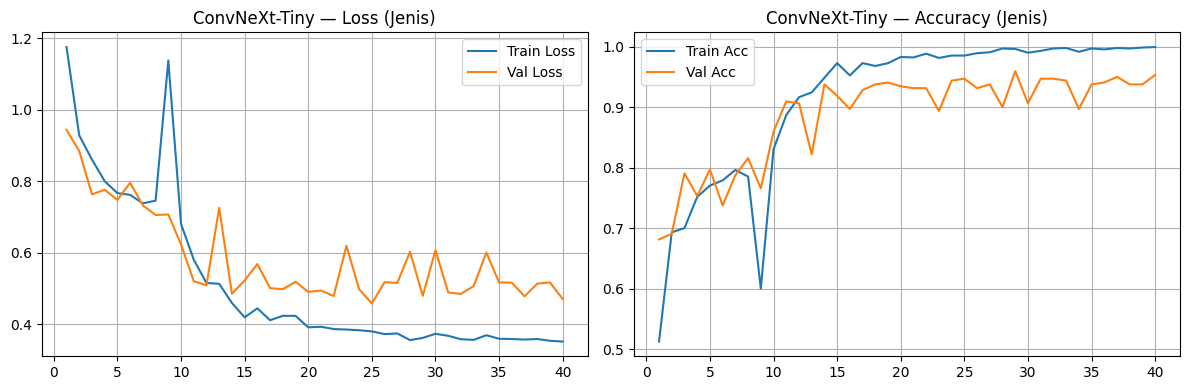


[INFO] Best Validation Accuracy Jenis Fold 1: 95.94%
>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<

[STAGE 2] Training 4 Model Sangrai untuk Fold 1...

--- Training Sangrai: Arabika (Fold 1) ---



[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Arabika
  MULAI TRAINING: CASCADE Arabika Fold 1 | Output: 4 Kelas | Max Epoch: 100
CASCADE Arabika Fold 1 | Epoch 01/100 | Train Loss: 0.9732 Acc: 64.06% | Val Loss: 0.6905 Acc: 78.75%
CASCADE Arabika Fold 1 | Epoch 05/100 | Train Loss: 0.5306 Acc: 92.19% | Val Loss: 0.4864 Acc: 92.50%
CASCADE Arabika Fold 1 | Epoch 10/100 | Train Loss: 0.5050 Acc: 92.50% | Val Loss: 0.4249 Acc: 97.50%
CASCADE Arabika Fold 1 | Epoch 15/100 | Train Loss: 0.3678 Acc: 100.00% | Val Loss: 0.3688 Acc: 98.75%
CASCADE Arabika Fold 1 | Epoch 20/100 | Train Loss: 0.3740 Acc: 98.75% | Val Loss: 0.4428 Acc: 96.25%
CASCADE Arabika Fold 1 | Epoch 25/100 | Train Loss: 0.3539 Acc: 100.00% | Val Loss: 0.3572 Acc: 98.75%
CASCADE Arabika Fold 1 | Epoch 30/100 | Train Loss: 0.3516 Acc: 100.00% | Val Loss: 0.3854 Acc: 97.50%
CASCADE Arabika Fold 1 | Epoch 35/100 | Train Loss: 0.3512 Acc: 100.00% | Val Loss: 0.4044 Acc: 96.25%
CASCADE Arabika Fold 1 | Epoch 40/100 | Tr

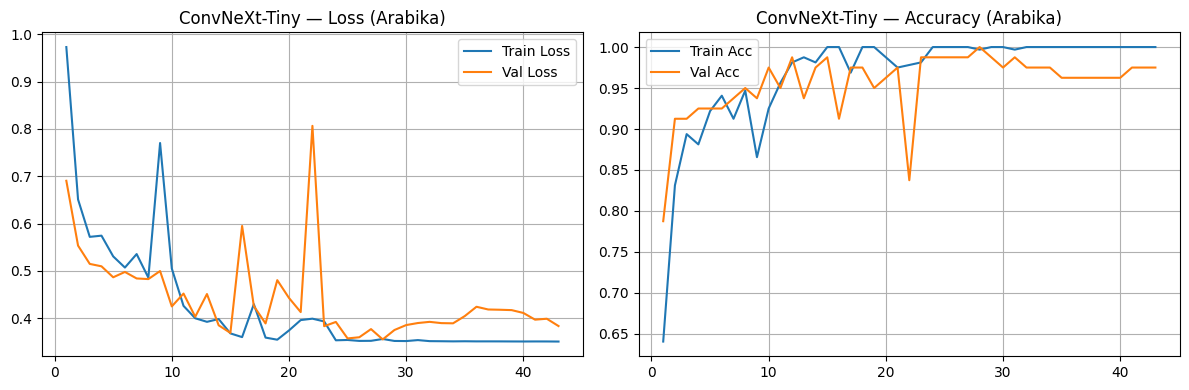


--- Training Sangrai: Ekselsa (Fold 1) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Ekselsa
  MULAI TRAINING: CASCADE Ekselsa Fold 1 | Output: 4 Kelas | Max Epoch: 100
CASCADE Ekselsa Fold 1 | Epoch 01/100 | Train Loss: 1.0438 Acc: 60.31% | Val Loss: 0.7690 Acc: 72.50%
CASCADE Ekselsa Fold 1 | Epoch 05/100 | Train Loss: 0.5063 Acc: 93.12% | Val Loss: 0.5276 Acc: 86.25%
CASCADE Ekselsa Fold 1 | Epoch 10/100 | Train Loss: 0.5109 Acc: 93.44% | Val Loss: 0.4338 Acc: 96.25%
CASCADE Ekselsa Fold 1 | Epoch 15/100 | Train Loss: 0.3781 Acc: 99.69% | Val Loss: 0.4274 Acc: 96.25%
CASCADE Ekselsa Fold 1 | Epoch 20/100 | Train Loss: 0.3696 Acc: 99.69% | Val Loss: 0.4084 Acc: 97.50%
CASCADE Ekselsa Fold 1 | Epoch 25/100 | Train Loss: 0.3580 Acc: 99.38% | Val Loss: 0.3932 Acc: 98.75%
CASCADE Ekselsa Fold 1 | Epoch 30/100 | Train Loss: 0.3517 Acc: 100.00% | Val Loss: 0.3631 Acc: 98.75%
CASCADE Ekselsa Fold 1 | Epoch 35/100 | Train Loss: 0.3510 Acc: 100.00% | Val Loss: 0.3946 Acc: 97.50%


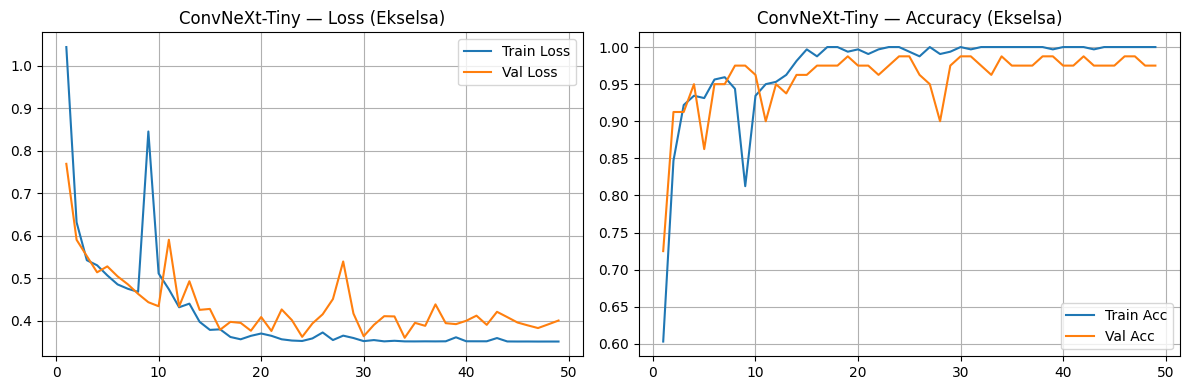


--- Training Sangrai: Liberika (Fold 1) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Liberika
  MULAI TRAINING: CASCADE Liberika Fold 1 | Output: 4 Kelas | Max Epoch: 100
CASCADE Liberika Fold 1 | Epoch 01/100 | Train Loss: 0.8810 Acc: 73.75% | Val Loss: 0.7108 Acc: 78.75%
CASCADE Liberika Fold 1 | Epoch 05/100 | Train Loss: 0.5031 Acc: 94.06% | Val Loss: 0.5035 Acc: 92.50%
CASCADE Liberika Fold 1 | Epoch 10/100 | Train Loss: 0.5402 Acc: 89.69% | Val Loss: 0.4212 Acc: 96.25%
CASCADE Liberika Fold 1 | Epoch 15/100 | Train Loss: 0.3886 Acc: 98.75% | Val Loss: 0.5328 Acc: 91.25%
CASCADE Liberika Fold 1 | Epoch 20/100 | Train Loss: 0.3714 Acc: 99.06% | Val Loss: 0.4008 Acc: 97.50%
CASCADE Liberika Fold 1 | Epoch 25/100 | Train Loss: 0.3547 Acc: 99.69% | Val Loss: 0.3888 Acc: 98.75%
CASCADE Liberika Fold 1 | Epoch 30/100 | Train Loss: 0.3556 Acc: 99.69% | Val Loss: 0.4468 Acc: 96.25%
CASCADE Liberika Fold 1 | Epoch 35/100 | Train Loss: 0.3509 Acc: 100.00% | Val Loss: 0.4141 Ac

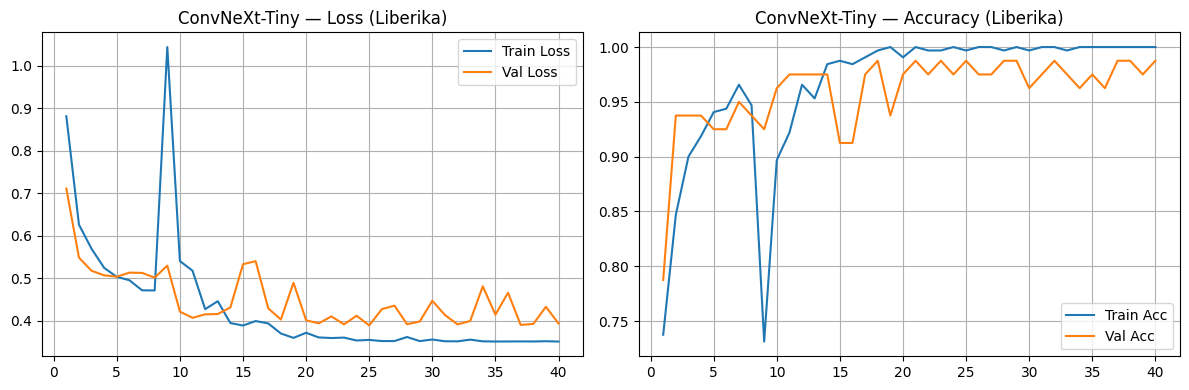


--- Training Sangrai: Robusta (Fold 1) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Robusta
  MULAI TRAINING: CASCADE Robusta Fold 1 | Output: 4 Kelas | Max Epoch: 100
CASCADE Robusta Fold 1 | Epoch 01/100 | Train Loss: 0.9207 Acc: 66.56% | Val Loss: 0.6495 Acc: 91.25%
CASCADE Robusta Fold 1 | Epoch 05/100 | Train Loss: 0.4906 Acc: 95.00% | Val Loss: 0.5343 Acc: 90.00%
CASCADE Robusta Fold 1 | Epoch 10/100 | Train Loss: 0.5555 Acc: 89.38% | Val Loss: 0.5240 Acc: 92.50%
CASCADE Robusta Fold 1 | Epoch 15/100 | Train Loss: 0.3862 Acc: 99.06% | Val Loss: 0.4205 Acc: 96.25%
CASCADE Robusta Fold 1 | Epoch 20/100 | Train Loss: 0.3556 Acc: 100.00% | Val Loss: 0.3916 Acc: 98.75%
CASCADE Robusta Fold 1 | Epoch 25/100 | Train Loss: 0.3520 Acc: 100.00% | Val Loss: 0.3509 Acc: 100.00%
CASCADE Robusta Fold 1 | Epoch 30/100 | Train Loss: 0.3574 Acc: 99.69% | Val Loss: 0.3994 Acc: 98.75%
CASCADE Robusta Fold 1 | Epoch 35/100 | Train Loss: 0.3512 Acc: 100.00% | Val Loss: 0.3692 Acc: 98.75

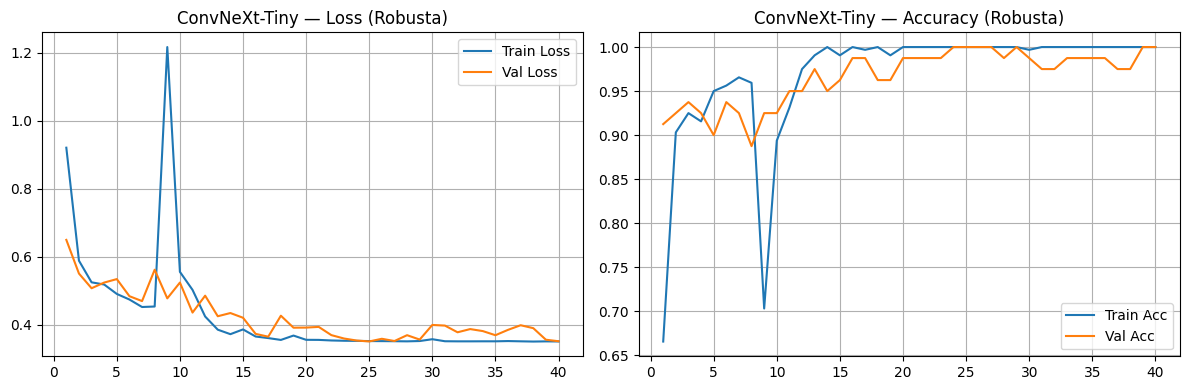


[EVALUASI CASCADE FOLD 1] Memulai evaluasi berantai 16 kelas...
[EVALUASI CASCADE FOLD 1] Selesai!
  Akurasi     : 95.31%
  F1 Macro    : 95.32%
  Precision M : 95.45%
  Recall M    : 95.31%

         CASCADE FOLD 2 (100 EPOCHS)

[STAGE 1] Training Model Jenis (4 Spesies)...

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Jenis
  MULAI TRAINING: CASCADE Jenis Fold 2 | Output: 4 Kelas | Max Epoch: 100
CASCADE Jenis Fold 2 | Epoch 01/100 | Train Loss: 1.1716 Acc: 51.48% | Val Loss: 0.9094 Acc: 67.50%
CASCADE Jenis Fold 2 | Epoch 05/100 | Train Loss: 0.7686 Acc: 77.03% | Val Loss: 0.7952 Acc: 73.75%
CASCADE Jenis Fold 2 | Epoch 10/100 | Train Loss: 0.7048 Acc: 80.94% | Val Loss: 0.7421 Acc: 79.69%
CASCADE Jenis Fold 2 | Epoch 15/100 | Train Loss: 0.4371 Acc: 96.09% | Val Loss: 0.4462 Acc: 94.38%
CASCADE Jenis Fold 2 | Epoch 20/100 | Train Loss: 0.3853 Acc: 98.36% | Val Loss: 0.5048 Acc: 92.50%
CASCADE Jenis Fold 2 | Epoch 25/100 | Train Loss: 0.3873 Acc: 98.36% | Val Loss: 0.5785 A

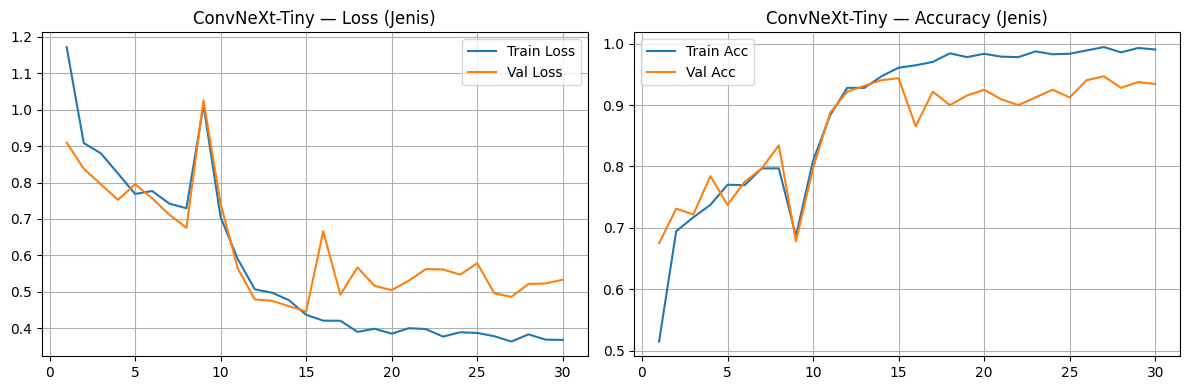


[INFO] Best Validation Accuracy Jenis Fold 2: 94.69%
>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<

[STAGE 2] Training 4 Model Sangrai untuk Fold 2...

--- Training Sangrai: Arabika (Fold 2) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Arabika
  MULAI TRAINING: CASCADE Arabika Fold 2 | Output: 4 Kelas | Max Epoch: 100
CASCADE Arabika Fold 2 | Epoch 01/100 | Train Loss: 0.9187 Acc: 66.56% | Val Loss: 0.6924 Acc: 80.00%
CASCADE Arabika Fold 2 | Epoch 05/100 | Train Loss: 0.5037 Acc: 93.12% | Val Loss: 0.5297 Acc: 91.25%
CASCADE Arabika Fold 2 | Epoch 10/100 | Train Loss: 0.4909 Acc: 93.75% | Val Loss: 0.4551 Acc: 96.25%
CASCADE Arabika Fold 2 | Epoch 15/100 | Train Loss: 0.3762 Acc: 99.06% | Val Loss: 0.4507 Acc: 95.00%
CASCADE Arabika Fold 2 | Epoch 20/100 | Train Loss: 0.3624 Acc: 99.69% | Val Loss: 0.3821 Acc: 98.75%
CASCADE Arabika Fold 2 | Epoch 25/100 | Train Loss: 0.3594 Acc: 99.69% | Val Loss: 0.4195 Acc: 95.00%
CASCADE Arabika Fold 2 | Epoch 30/100 | Train

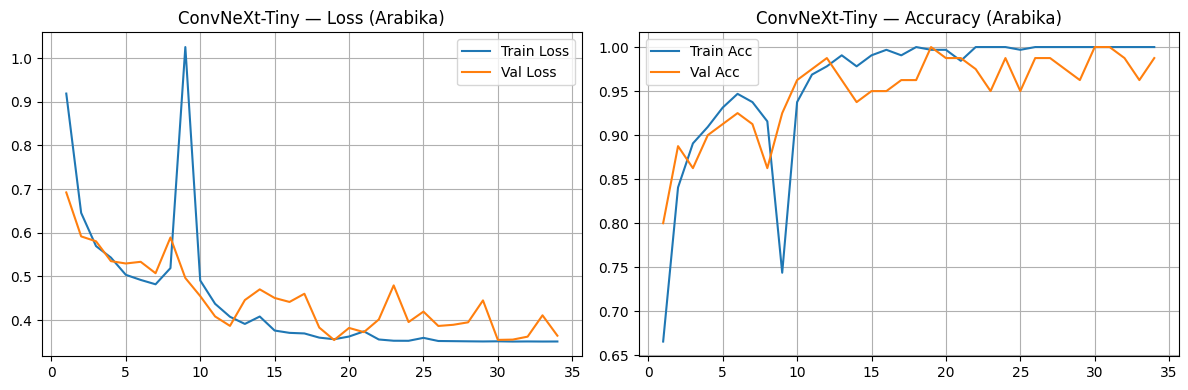


--- Training Sangrai: Ekselsa (Fold 2) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Ekselsa
  MULAI TRAINING: CASCADE Ekselsa Fold 2 | Output: 4 Kelas | Max Epoch: 100
CASCADE Ekselsa Fold 2 | Epoch 01/100 | Train Loss: 1.0173 Acc: 64.69% | Val Loss: 0.7626 Acc: 72.50%
CASCADE Ekselsa Fold 2 | Epoch 05/100 | Train Loss: 0.5201 Acc: 93.44% | Val Loss: 0.5397 Acc: 93.75%
CASCADE Ekselsa Fold 2 | Epoch 10/100 | Train Loss: 0.4637 Acc: 94.38% | Val Loss: 0.4549 Acc: 97.50%
CASCADE Ekselsa Fold 2 | Epoch 15/100 | Train Loss: 0.3725 Acc: 99.38% | Val Loss: 0.4344 Acc: 96.25%
CASCADE Ekselsa Fold 2 | Epoch 20/100 | Train Loss: 0.3540 Acc: 100.00% | Val Loss: 0.4068 Acc: 97.50%
CASCADE Ekselsa Fold 2 | Epoch 25/100 | Train Loss: 0.3602 Acc: 99.69% | Val Loss: 0.4489 Acc: 95.00%
CASCADE Ekselsa Fold 2 | Epoch 30/100 | Train Loss: 0.3520 Acc: 100.00% | Val Loss: 0.4162 Acc: 97.50%
CASCADE Ekselsa Fold 2 | Epoch 35/100 | Train Loss: 0.3510 Acc: 100.00% | Val Loss: 0.4062 Acc: 97.50%

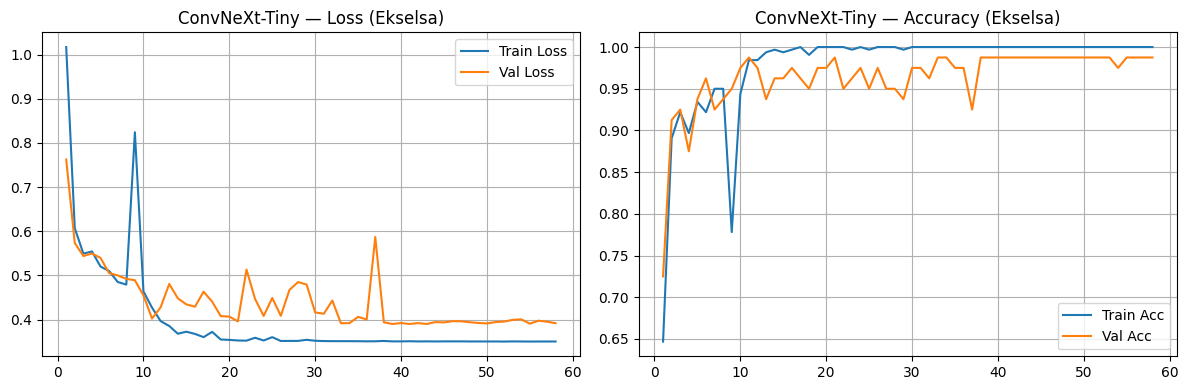


--- Training Sangrai: Liberika (Fold 2) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Liberika
  MULAI TRAINING: CASCADE Liberika Fold 2 | Output: 4 Kelas | Max Epoch: 100
CASCADE Liberika Fold 2 | Epoch 01/100 | Train Loss: 0.9127 Acc: 66.88% | Val Loss: 0.5982 Acc: 92.50%
CASCADE Liberika Fold 2 | Epoch 05/100 | Train Loss: 0.5226 Acc: 92.50% | Val Loss: 0.4957 Acc: 96.25%
CASCADE Liberika Fold 2 | Epoch 10/100 | Train Loss: 0.4779 Acc: 95.31% | Val Loss: 0.4431 Acc: 93.75%
CASCADE Liberika Fold 2 | Epoch 15/100 | Train Loss: 0.3848 Acc: 99.38% | Val Loss: 0.5058 Acc: 93.75%
CASCADE Liberika Fold 2 | Epoch 20/100 | Train Loss: 0.3747 Acc: 99.06% | Val Loss: 0.5767 Acc: 93.75%
CASCADE Liberika Fold 2 | Epoch 25/100 | Train Loss: 0.3803 Acc: 98.75% | Val Loss: 0.4959 Acc: 95.00%
[Early Stopping] CASCADE Liberika Fold 2 berhenti di epoch 29.
=> CASCADE Liberika Fold 2 Selesai! Best Val Accuracy: 98.75%


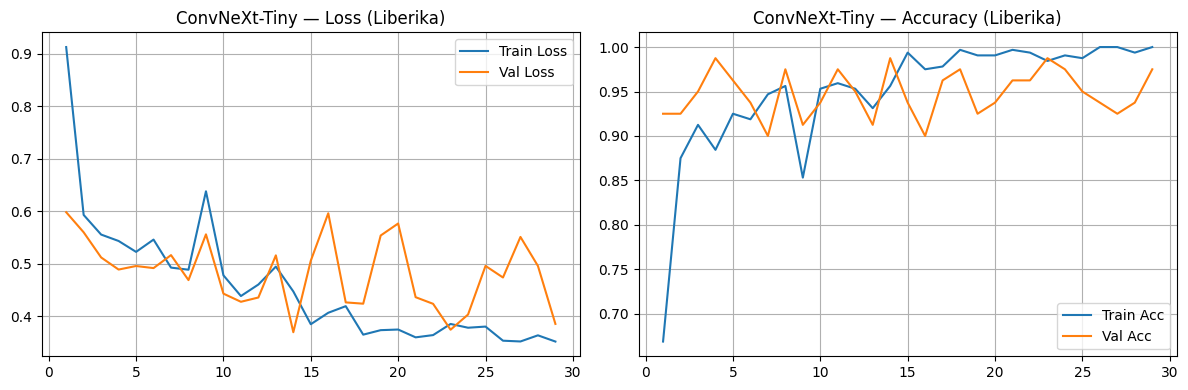


--- Training Sangrai: Robusta (Fold 2) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Robusta
  MULAI TRAINING: CASCADE Robusta Fold 2 | Output: 4 Kelas | Max Epoch: 100
CASCADE Robusta Fold 2 | Epoch 01/100 | Train Loss: 0.9794 Acc: 66.25% | Val Loss: 0.6643 Acc: 83.75%
CASCADE Robusta Fold 2 | Epoch 05/100 | Train Loss: 0.4871 Acc: 95.62% | Val Loss: 0.5557 Acc: 87.50%
CASCADE Robusta Fold 2 | Epoch 10/100 | Train Loss: 0.5852 Acc: 89.69% | Val Loss: 0.5784 Acc: 92.50%
CASCADE Robusta Fold 2 | Epoch 15/100 | Train Loss: 0.3630 Acc: 100.00% | Val Loss: 0.3978 Acc: 98.75%
CASCADE Robusta Fold 2 | Epoch 20/100 | Train Loss: 0.3566 Acc: 99.69% | Val Loss: 0.3965 Acc: 98.75%
CASCADE Robusta Fold 2 | Epoch 25/100 | Train Loss: 0.3532 Acc: 100.00% | Val Loss: 0.3965 Acc: 98.75%
CASCADE Robusta Fold 2 | Epoch 30/100 | Train Loss: 0.3512 Acc: 100.00% | Val Loss: 0.3968 Acc: 98.75%
CASCADE Robusta Fold 2 | Epoch 35/100 | Train Loss: 0.3509 Acc: 100.00% | Val Loss: 0.4090 Acc: 97.50

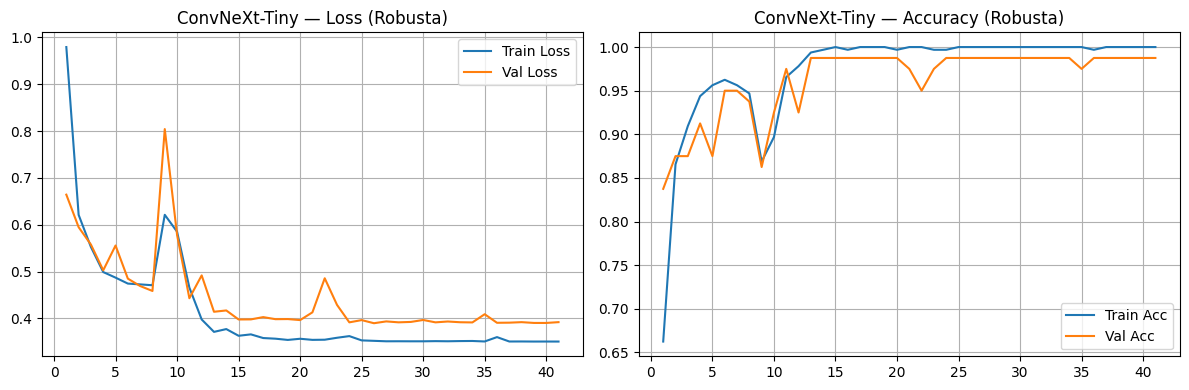


[EVALUASI CASCADE FOLD 2] Memulai evaluasi berantai 16 kelas...
[EVALUASI CASCADE FOLD 2] Selesai!
  Akurasi     : 93.75%
  F1 Macro    : 93.60%
  Precision M : 94.37%
  Recall M    : 93.75%

         CASCADE FOLD 3 (100 EPOCHS)

[STAGE 1] Training Model Jenis (4 Spesies)...

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Jenis
  MULAI TRAINING: CASCADE Jenis Fold 3 | Output: 4 Kelas | Max Epoch: 100
CASCADE Jenis Fold 3 | Epoch 01/100 | Train Loss: 1.1675 Acc: 52.11% | Val Loss: 0.9753 Acc: 64.69%
CASCADE Jenis Fold 3 | Epoch 05/100 | Train Loss: 0.7823 Acc: 76.72% | Val Loss: 0.7763 Acc: 75.62%
CASCADE Jenis Fold 3 | Epoch 10/100 | Train Loss: 0.6803 Acc: 81.95% | Val Loss: 0.5837 Acc: 86.88%
CASCADE Jenis Fold 3 | Epoch 15/100 | Train Loss: 0.4352 Acc: 96.41% | Val Loss: 0.5103 Acc: 91.56%
CASCADE Jenis Fold 3 | Epoch 20/100 | Train Loss: 0.3926 Acc: 98.28% | Val Loss: 0.5225 Acc: 92.19%
CASCADE Jenis Fold 3 | Epoch 25/100 | Train Loss: 0.3879 Acc: 98.12% | Val Loss: 0.6477 A

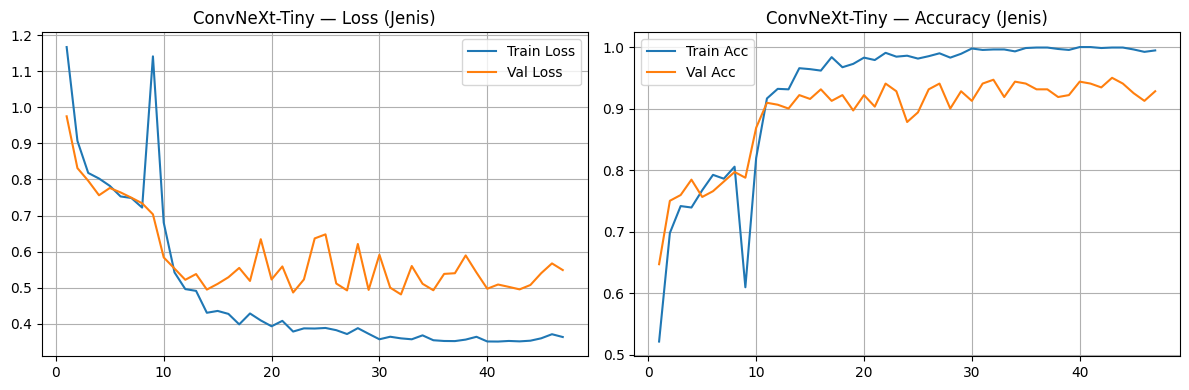


[INFO] Best Validation Accuracy Jenis Fold 3: 95.00%
>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<

[STAGE 2] Training 4 Model Sangrai untuk Fold 3...

--- Training Sangrai: Arabika (Fold 3) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Arabika
  MULAI TRAINING: CASCADE Arabika Fold 3 | Output: 4 Kelas | Max Epoch: 100
CASCADE Arabika Fold 3 | Epoch 01/100 | Train Loss: 0.9057 Acc: 68.12% | Val Loss: 0.6460 Acc: 87.50%
CASCADE Arabika Fold 3 | Epoch 05/100 | Train Loss: 0.5464 Acc: 90.31% | Val Loss: 0.5544 Acc: 90.00%
CASCADE Arabika Fold 3 | Epoch 10/100 | Train Loss: 0.4613 Acc: 96.25% | Val Loss: 0.4238 Acc: 93.75%
CASCADE Arabika Fold 3 | Epoch 15/100 | Train Loss: 0.3898 Acc: 98.44% | Val Loss: 0.4171 Acc: 96.25%
CASCADE Arabika Fold 3 | Epoch 20/100 | Train Loss: 0.3662 Acc: 99.38% | Val Loss: 0.4877 Acc: 93.75%
CASCADE Arabika Fold 3 | Epoch 25/100 | Train Loss: 0.3532 Acc: 100.00% | Val Loss: 0.4270 Acc: 96.25%
CASCADE Arabika Fold 3 | Epoch 30/100 | Trai

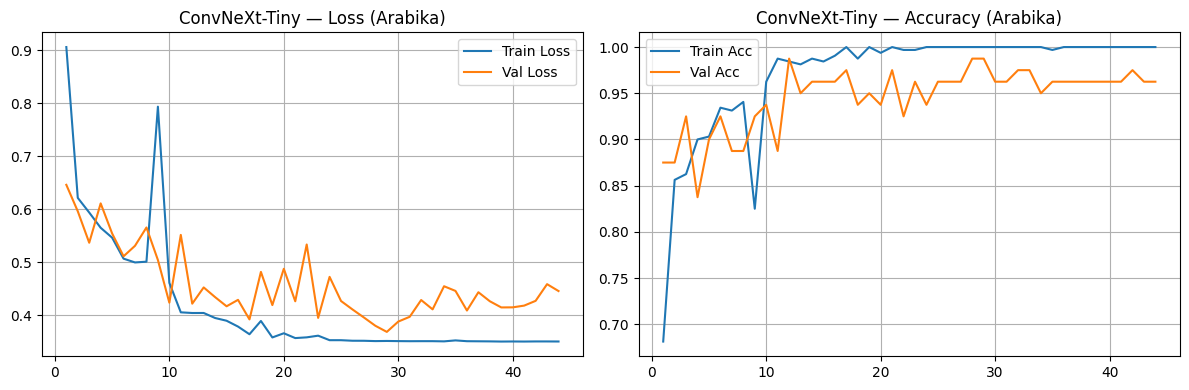


--- Training Sangrai: Ekselsa (Fold 3) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Ekselsa
  MULAI TRAINING: CASCADE Ekselsa Fold 3 | Output: 4 Kelas | Max Epoch: 100
CASCADE Ekselsa Fold 3 | Epoch 01/100 | Train Loss: 0.9961 Acc: 65.62% | Val Loss: 0.7348 Acc: 75.00%
CASCADE Ekselsa Fold 3 | Epoch 05/100 | Train Loss: 0.5004 Acc: 94.69% | Val Loss: 0.6014 Acc: 83.75%
CASCADE Ekselsa Fold 3 | Epoch 10/100 | Train Loss: 0.5438 Acc: 91.88% | Val Loss: 0.4682 Acc: 95.00%
CASCADE Ekselsa Fold 3 | Epoch 15/100 | Train Loss: 0.3791 Acc: 99.38% | Val Loss: 0.3887 Acc: 97.50%
CASCADE Ekselsa Fold 3 | Epoch 20/100 | Train Loss: 0.3559 Acc: 100.00% | Val Loss: 0.3628 Acc: 98.75%
CASCADE Ekselsa Fold 3 | Epoch 25/100 | Train Loss: 0.3516 Acc: 100.00% | Val Loss: 0.3595 Acc: 100.00%
CASCADE Ekselsa Fold 3 | Epoch 30/100 | Train Loss: 0.3513 Acc: 100.00% | Val Loss: 0.4300 Acc: 96.25%
CASCADE Ekselsa Fold 3 | Epoch 35/100 | Train Loss: 0.3509 Acc: 100.00% | Val Loss: 0.4300 Acc: 97.5

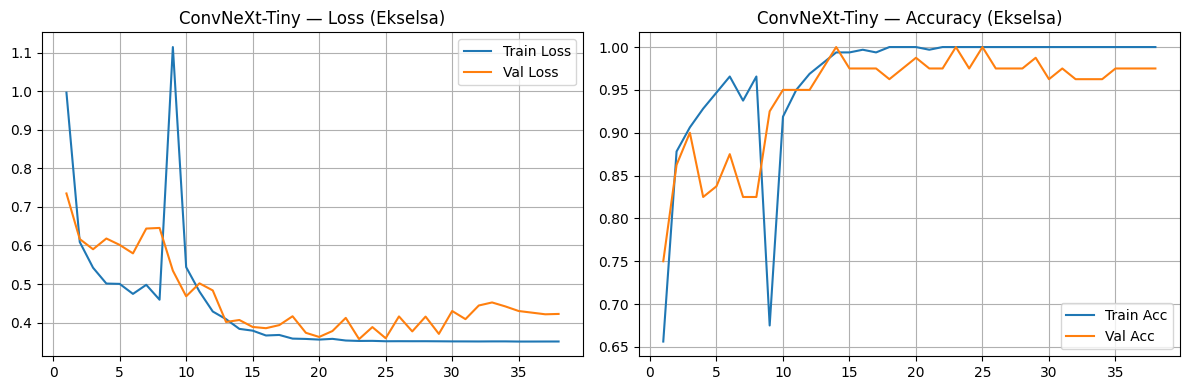


--- Training Sangrai: Liberika (Fold 3) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Liberika
  MULAI TRAINING: CASCADE Liberika Fold 3 | Output: 4 Kelas | Max Epoch: 100
CASCADE Liberika Fold 3 | Epoch 01/100 | Train Loss: 0.9982 Acc: 61.88% | Val Loss: 0.6210 Acc: 88.75%
CASCADE Liberika Fold 3 | Epoch 05/100 | Train Loss: 0.5462 Acc: 90.00% | Val Loss: 0.5675 Acc: 85.00%
CASCADE Liberika Fold 3 | Epoch 10/100 | Train Loss: 0.4994 Acc: 93.44% | Val Loss: 0.4805 Acc: 93.75%
CASCADE Liberika Fold 3 | Epoch 15/100 | Train Loss: 0.3799 Acc: 99.06% | Val Loss: 0.4984 Acc: 96.25%
CASCADE Liberika Fold 3 | Epoch 20/100 | Train Loss: 0.3694 Acc: 99.69% | Val Loss: 0.4485 Acc: 96.25%
CASCADE Liberika Fold 3 | Epoch 25/100 | Train Loss: 0.3593 Acc: 99.69% | Val Loss: 0.4490 Acc: 96.25%
[Early Stopping] CASCADE Liberika Fold 3 berhenti di epoch 29.
=> CASCADE Liberika Fold 3 Selesai! Best Val Accuracy: 97.50%


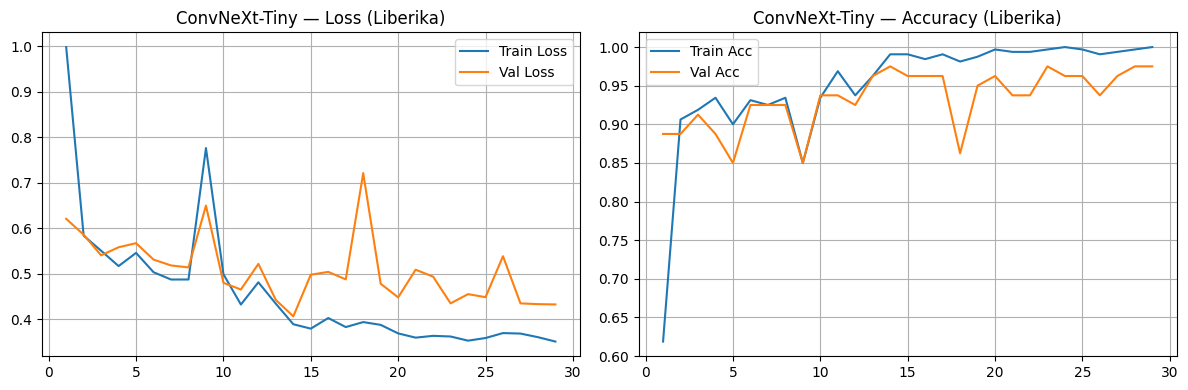


--- Training Sangrai: Robusta (Fold 3) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Robusta
  MULAI TRAINING: CASCADE Robusta Fold 3 | Output: 4 Kelas | Max Epoch: 100
CASCADE Robusta Fold 3 | Epoch 01/100 | Train Loss: 0.9690 Acc: 61.88% | Val Loss: 0.6797 Acc: 80.00%
CASCADE Robusta Fold 3 | Epoch 05/100 | Train Loss: 0.5048 Acc: 92.81% | Val Loss: 0.4502 Acc: 96.25%
CASCADE Robusta Fold 3 | Epoch 10/100 | Train Loss: 0.4566 Acc: 95.31% | Val Loss: 0.4866 Acc: 95.00%
CASCADE Robusta Fold 3 | Epoch 15/100 | Train Loss: 0.3705 Acc: 99.06% | Val Loss: 0.3697 Acc: 100.00%
CASCADE Robusta Fold 3 | Epoch 20/100 | Train Loss: 0.3626 Acc: 99.69% | Val Loss: 0.3614 Acc: 98.75%
CASCADE Robusta Fold 3 | Epoch 25/100 | Train Loss: 0.3521 Acc: 100.00% | Val Loss: 0.3547 Acc: 100.00%
CASCADE Robusta Fold 3 | Epoch 30/100 | Train Loss: 0.3515 Acc: 100.00% | Val Loss: 0.3499 Acc: 100.00%
CASCADE Robusta Fold 3 | Epoch 35/100 | Train Loss: 0.3510 Acc: 100.00% | Val Loss: 0.3503 Acc: 100

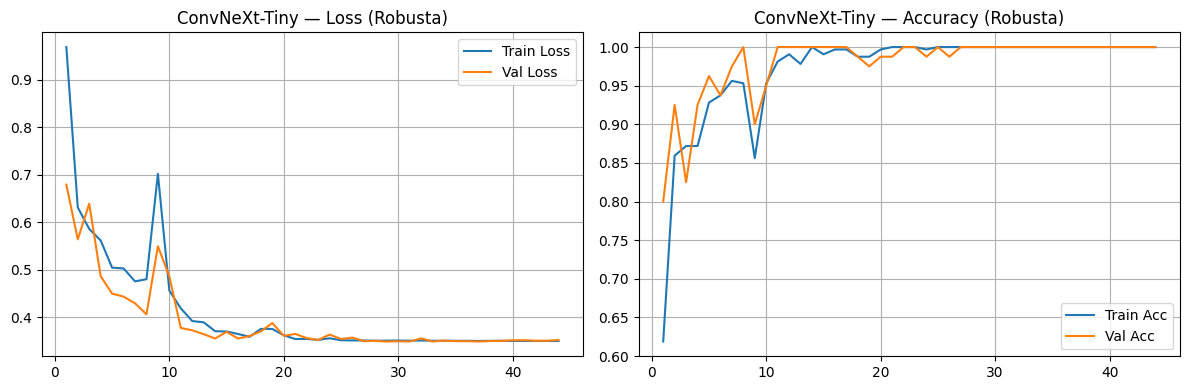


[EVALUASI CASCADE FOLD 3] Memulai evaluasi berantai 16 kelas...
[EVALUASI CASCADE FOLD 3] Selesai!
  Akurasi     : 94.06%
  F1 Macro    : 93.86%
  Precision M : 94.98%
  Recall M    : 94.06%

         CASCADE FOLD 4 (100 EPOCHS)

[STAGE 1] Training Model Jenis (4 Spesies)...

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Jenis
  MULAI TRAINING: CASCADE Jenis Fold 4 | Output: 4 Kelas | Max Epoch: 100
CASCADE Jenis Fold 4 | Epoch 01/100 | Train Loss: 1.2100 Acc: 49.38% | Val Loss: 1.0728 Acc: 62.81%
CASCADE Jenis Fold 4 | Epoch 05/100 | Train Loss: 0.7523 Acc: 78.28% | Val Loss: 0.7754 Acc: 80.00%
CASCADE Jenis Fold 4 | Epoch 10/100 | Train Loss: 0.6234 Acc: 85.62% | Val Loss: 0.5341 Acc: 91.25%
CASCADE Jenis Fold 4 | Epoch 15/100 | Train Loss: 0.4328 Acc: 96.41% | Val Loss: 0.6587 Acc: 84.06%
CASCADE Jenis Fold 4 | Epoch 20/100 | Train Loss: 0.3812 Acc: 98.75% | Val Loss: 0.5024 Acc: 93.44%
CASCADE Jenis Fold 4 | Epoch 25/100 | Train Loss: 0.3914 Acc: 98.36% | Val Loss: 0.5035 A

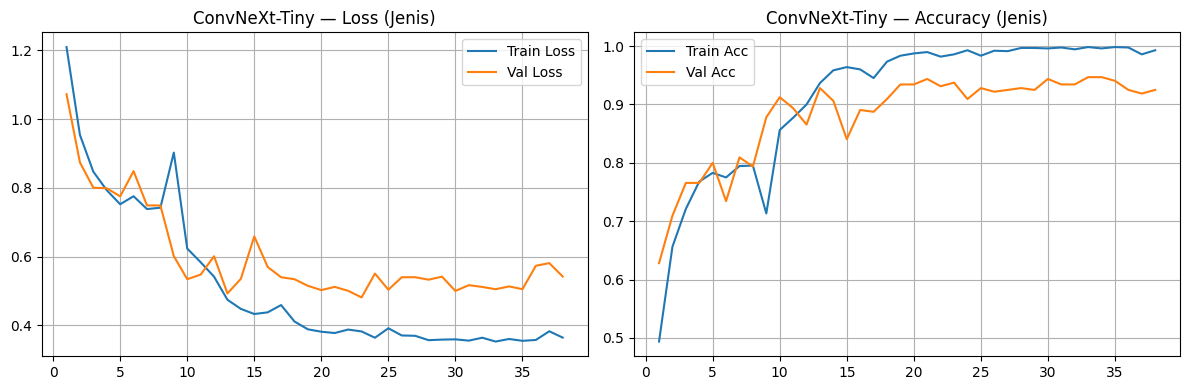


[INFO] Best Validation Accuracy Jenis Fold 4: 94.69%
>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<

[STAGE 2] Training 4 Model Sangrai untuk Fold 4...

--- Training Sangrai: Arabika (Fold 4) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Arabika
  MULAI TRAINING: CASCADE Arabika Fold 4 | Output: 4 Kelas | Max Epoch: 100
CASCADE Arabika Fold 4 | Epoch 01/100 | Train Loss: 0.9246 Acc: 67.50% | Val Loss: 0.6197 Acc: 92.50%
CASCADE Arabika Fold 4 | Epoch 05/100 | Train Loss: 0.5265 Acc: 90.62% | Val Loss: 0.5054 Acc: 91.25%
CASCADE Arabika Fold 4 | Epoch 10/100 | Train Loss: 0.4619 Acc: 95.31% | Val Loss: 0.4381 Acc: 97.50%
CASCADE Arabika Fold 4 | Epoch 15/100 | Train Loss: 0.3673 Acc: 99.69% | Val Loss: 0.4121 Acc: 97.50%
CASCADE Arabika Fold 4 | Epoch 20/100 | Train Loss: 0.3693 Acc: 99.69% | Val Loss: 0.6140 Acc: 91.25%
CASCADE Arabika Fold 4 | Epoch 25/100 | Train Loss: 0.3527 Acc: 100.00% | Val Loss: 0.3540 Acc: 100.00%
CASCADE Arabika Fold 4 | Epoch 30/100 | Tra

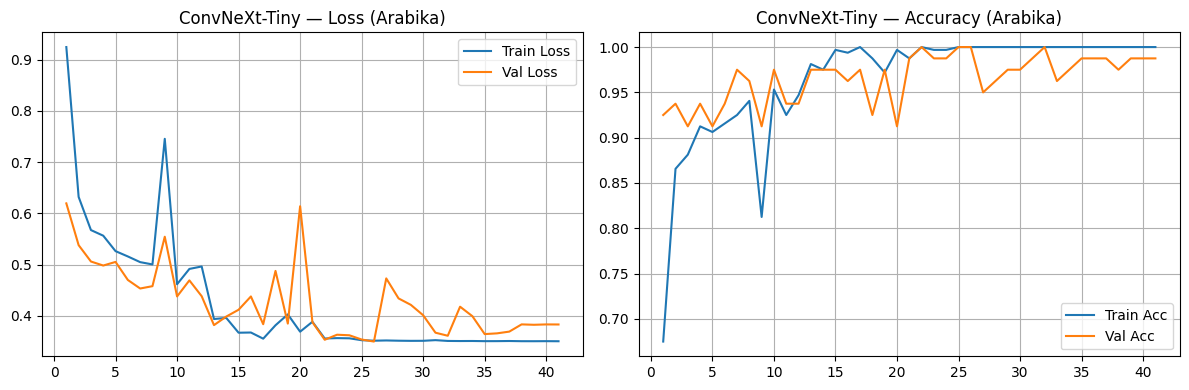


--- Training Sangrai: Ekselsa (Fold 4) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Ekselsa
  MULAI TRAINING: CASCADE Ekselsa Fold 4 | Output: 4 Kelas | Max Epoch: 100
CASCADE Ekselsa Fold 4 | Epoch 01/100 | Train Loss: 1.0746 Acc: 61.56% | Val Loss: 0.8024 Acc: 73.75%
CASCADE Ekselsa Fold 4 | Epoch 05/100 | Train Loss: 0.5012 Acc: 93.44% | Val Loss: 0.5372 Acc: 91.25%
CASCADE Ekselsa Fold 4 | Epoch 10/100 | Train Loss: 0.5222 Acc: 93.12% | Val Loss: 0.5103 Acc: 96.25%
CASCADE Ekselsa Fold 4 | Epoch 15/100 | Train Loss: 0.4030 Acc: 97.50% | Val Loss: 0.4440 Acc: 96.25%
CASCADE Ekselsa Fold 4 | Epoch 20/100 | Train Loss: 0.3586 Acc: 99.69% | Val Loss: 0.4175 Acc: 97.50%
CASCADE Ekselsa Fold 4 | Epoch 25/100 | Train Loss: 0.3523 Acc: 100.00% | Val Loss: 0.3655 Acc: 98.75%
CASCADE Ekselsa Fold 4 | Epoch 30/100 | Train Loss: 0.3511 Acc: 100.00% | Val Loss: 0.4875 Acc: 95.00%
CASCADE Ekselsa Fold 4 | Epoch 35/100 | Train Loss: 0.3521 Acc: 100.00% | Val Loss: 0.3748 Acc: 98.75%

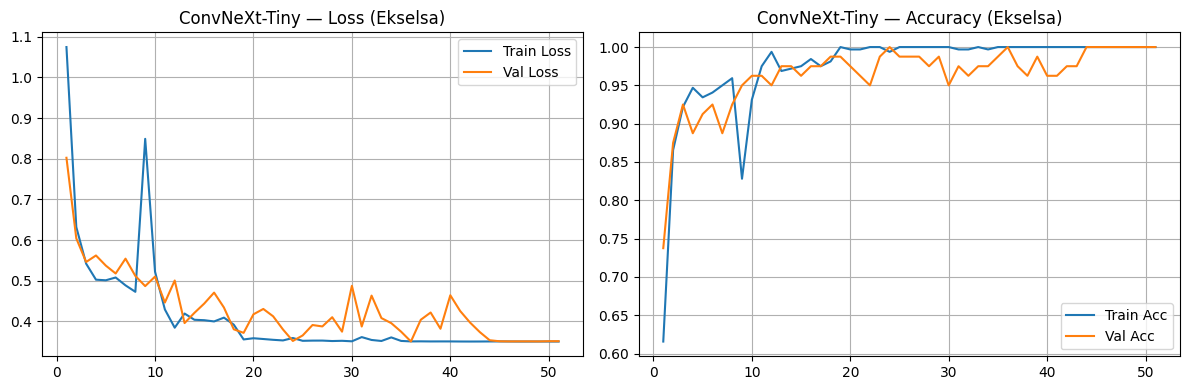


--- Training Sangrai: Liberika (Fold 4) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Liberika
  MULAI TRAINING: CASCADE Liberika Fold 4 | Output: 4 Kelas | Max Epoch: 100
CASCADE Liberika Fold 4 | Epoch 01/100 | Train Loss: 0.9398 Acc: 66.25% | Val Loss: 0.7993 Acc: 70.00%
CASCADE Liberika Fold 4 | Epoch 05/100 | Train Loss: 0.5154 Acc: 92.81% | Val Loss: 0.5542 Acc: 91.25%
CASCADE Liberika Fold 4 | Epoch 10/100 | Train Loss: 0.4844 Acc: 93.44% | Val Loss: 0.5254 Acc: 92.50%
CASCADE Liberika Fold 4 | Epoch 15/100 | Train Loss: 0.4306 Acc: 97.81% | Val Loss: 0.4511 Acc: 96.25%
CASCADE Liberika Fold 4 | Epoch 20/100 | Train Loss: 0.3967 Acc: 97.19% | Val Loss: 0.4828 Acc: 95.00%
CASCADE Liberika Fold 4 | Epoch 25/100 | Train Loss: 0.3728 Acc: 99.06% | Val Loss: 0.4629 Acc: 95.00%
CASCADE Liberika Fold 4 | Epoch 30/100 | Train Loss: 0.3520 Acc: 100.00% | Val Loss: 0.4640 Acc: 96.25%
CASCADE Liberika Fold 4 | Epoch 35/100 | Train Loss: 0.3522 Acc: 100.00% | Val Loss: 0.4624 A

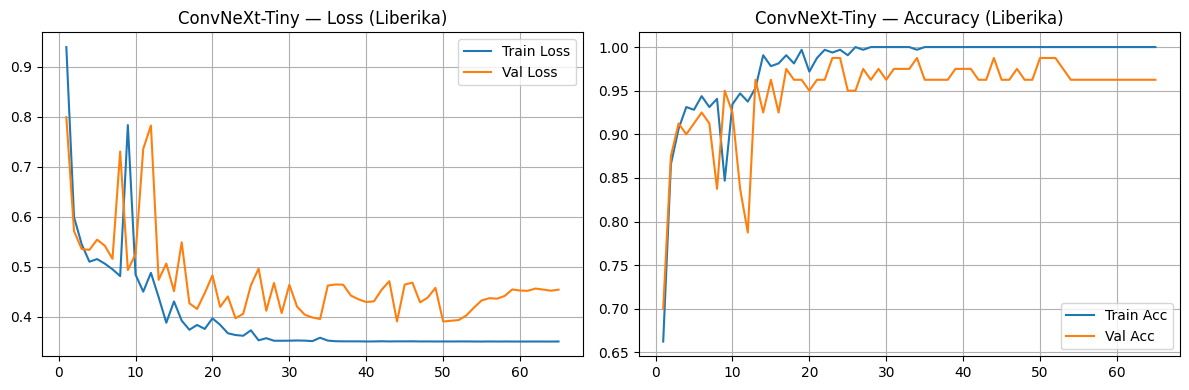


--- Training Sangrai: Robusta (Fold 4) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Robusta
  MULAI TRAINING: CASCADE Robusta Fold 4 | Output: 4 Kelas | Max Epoch: 100
CASCADE Robusta Fold 4 | Epoch 01/100 | Train Loss: 0.9919 Acc: 63.75% | Val Loss: 0.7326 Acc: 70.00%
CASCADE Robusta Fold 4 | Epoch 05/100 | Train Loss: 0.4815 Acc: 95.31% | Val Loss: 0.5118 Acc: 91.25%
CASCADE Robusta Fold 4 | Epoch 10/100 | Train Loss: 0.4559 Acc: 95.00% | Val Loss: 0.7271 Acc: 81.25%
CASCADE Robusta Fold 4 | Epoch 15/100 | Train Loss: 0.4042 Acc: 97.81% | Val Loss: 0.4305 Acc: 97.50%
CASCADE Robusta Fold 4 | Epoch 20/100 | Train Loss: 0.3601 Acc: 100.00% | Val Loss: 0.4156 Acc: 97.50%
CASCADE Robusta Fold 4 | Epoch 25/100 | Train Loss: 0.3520 Acc: 100.00% | Val Loss: 0.4276 Acc: 97.50%
CASCADE Robusta Fold 4 | Epoch 30/100 | Train Loss: 0.3511 Acc: 100.00% | Val Loss: 0.3937 Acc: 98.75%
CASCADE Robusta Fold 4 | Epoch 35/100 | Train Loss: 0.3510 Acc: 100.00% | Val Loss: 0.3970 Acc: 98.75

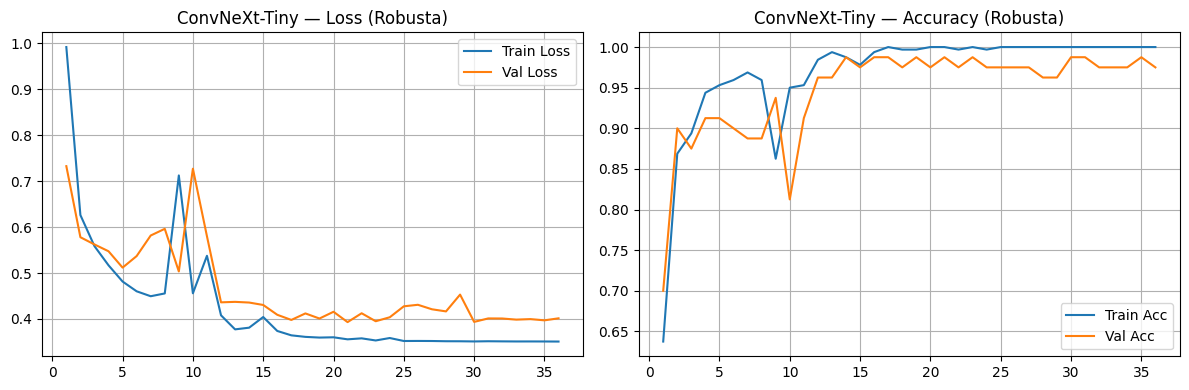


[EVALUASI CASCADE FOLD 4] Memulai evaluasi berantai 16 kelas...
[EVALUASI CASCADE FOLD 4] Selesai!
  Akurasi     : 94.06%
  F1 Macro    : 93.91%
  Precision M : 94.25%
  Recall M    : 94.06%

         CASCADE FOLD 5 (100 EPOCHS)

[STAGE 1] Training Model Jenis (4 Spesies)...

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Jenis
  MULAI TRAINING: CASCADE Jenis Fold 5 | Output: 4 Kelas | Max Epoch: 100
CASCADE Jenis Fold 5 | Epoch 01/100 | Train Loss: 1.1866 Acc: 50.16% | Val Loss: 0.9664 Acc: 67.81%
CASCADE Jenis Fold 5 | Epoch 05/100 | Train Loss: 0.7873 Acc: 75.23% | Val Loss: 0.7955 Acc: 74.69%
CASCADE Jenis Fold 5 | Epoch 10/100 | Train Loss: 0.6642 Acc: 83.91% | Val Loss: 0.6872 Acc: 83.44%
CASCADE Jenis Fold 5 | Epoch 15/100 | Train Loss: 0.4535 Acc: 95.39% | Val Loss: 0.5718 Acc: 90.00%
CASCADE Jenis Fold 5 | Epoch 20/100 | Train Loss: 0.3782 Acc: 98.75% | Val Loss: 0.4953 Acc: 93.75%
CASCADE Jenis Fold 5 | Epoch 25/100 | Train Loss: 0.3613 Acc: 99.38% | Val Loss: 0.4894 A

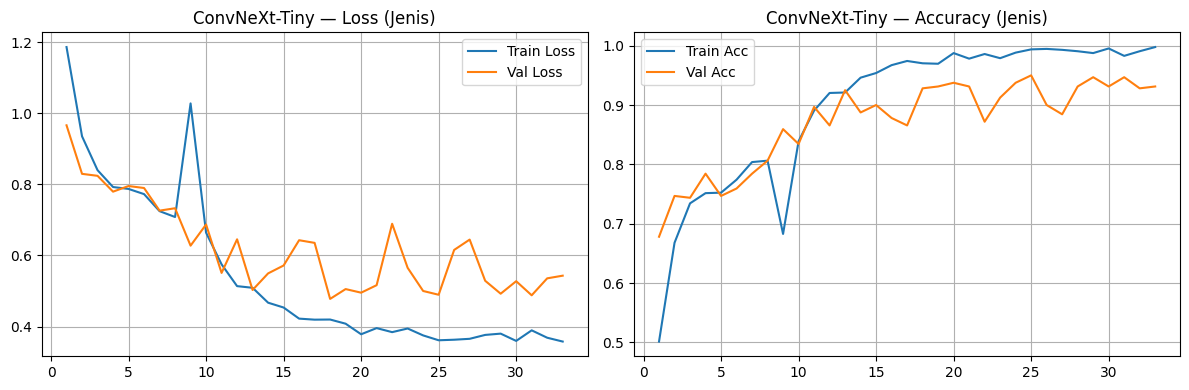


[INFO] Best Validation Accuracy Jenis Fold 5: 95.00%
>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<

[STAGE 2] Training 4 Model Sangrai untuk Fold 5...

--- Training Sangrai: Arabika (Fold 5) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Arabika
  MULAI TRAINING: CASCADE Arabika Fold 5 | Output: 4 Kelas | Max Epoch: 100
CASCADE Arabika Fold 5 | Epoch 01/100 | Train Loss: 0.9115 Acc: 66.88% | Val Loss: 0.6296 Acc: 86.25%
CASCADE Arabika Fold 5 | Epoch 05/100 | Train Loss: 0.5326 Acc: 93.44% | Val Loss: 0.5427 Acc: 91.25%
CASCADE Arabika Fold 5 | Epoch 10/100 | Train Loss: 0.5689 Acc: 89.69% | Val Loss: 0.5068 Acc: 92.50%
CASCADE Arabika Fold 5 | Epoch 15/100 | Train Loss: 0.3877 Acc: 99.06% | Val Loss: 0.4504 Acc: 96.25%
CASCADE Arabika Fold 5 | Epoch 20/100 | Train Loss: 0.3633 Acc: 99.69% | Val Loss: 0.3978 Acc: 96.25%
CASCADE Arabika Fold 5 | Epoch 25/100 | Train Loss: 0.3521 Acc: 100.00% | Val Loss: 0.4732 Acc: 95.00%
CASCADE Arabika Fold 5 | Epoch 30/100 | Trai

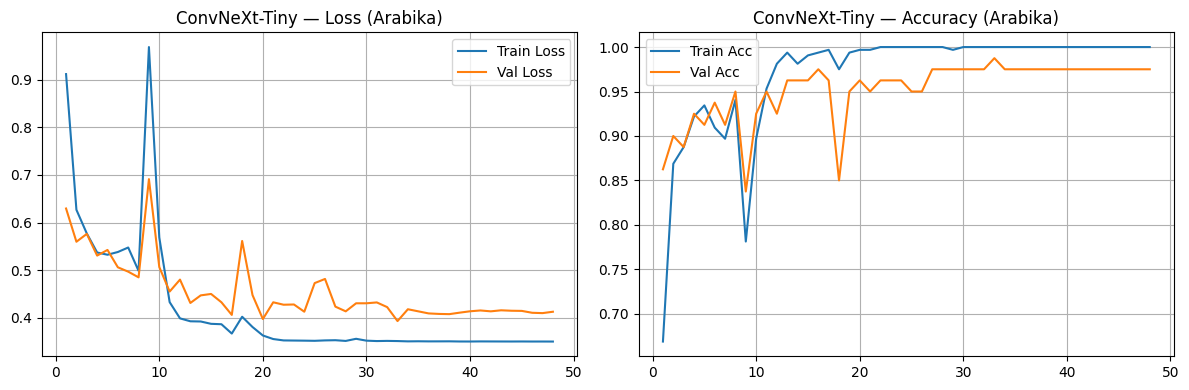


--- Training Sangrai: Ekselsa (Fold 5) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Ekselsa
  MULAI TRAINING: CASCADE Ekselsa Fold 5 | Output: 4 Kelas | Max Epoch: 100
CASCADE Ekselsa Fold 5 | Epoch 01/100 | Train Loss: 0.9750 Acc: 66.25% | Val Loss: 0.7139 Acc: 82.50%
CASCADE Ekselsa Fold 5 | Epoch 05/100 | Train Loss: 0.5016 Acc: 94.38% | Val Loss: 0.5194 Acc: 91.25%
CASCADE Ekselsa Fold 5 | Epoch 10/100 | Train Loss: 0.4771 Acc: 95.00% | Val Loss: 0.4499 Acc: 95.00%
CASCADE Ekselsa Fold 5 | Epoch 15/100 | Train Loss: 0.3796 Acc: 99.38% | Val Loss: 0.4417 Acc: 95.00%
CASCADE Ekselsa Fold 5 | Epoch 20/100 | Train Loss: 0.3540 Acc: 100.00% | Val Loss: 0.4268 Acc: 96.25%
CASCADE Ekselsa Fold 5 | Epoch 25/100 | Train Loss: 0.3540 Acc: 100.00% | Val Loss: 0.4295 Acc: 96.25%
CASCADE Ekselsa Fold 5 | Epoch 30/100 | Train Loss: 0.3514 Acc: 100.00% | Val Loss: 0.4548 Acc: 96.25%
[Early Stopping] CASCADE Ekselsa Fold 5 berhenti di epoch 32.
=> CASCADE Ekselsa Fold 5 Selesai! Best

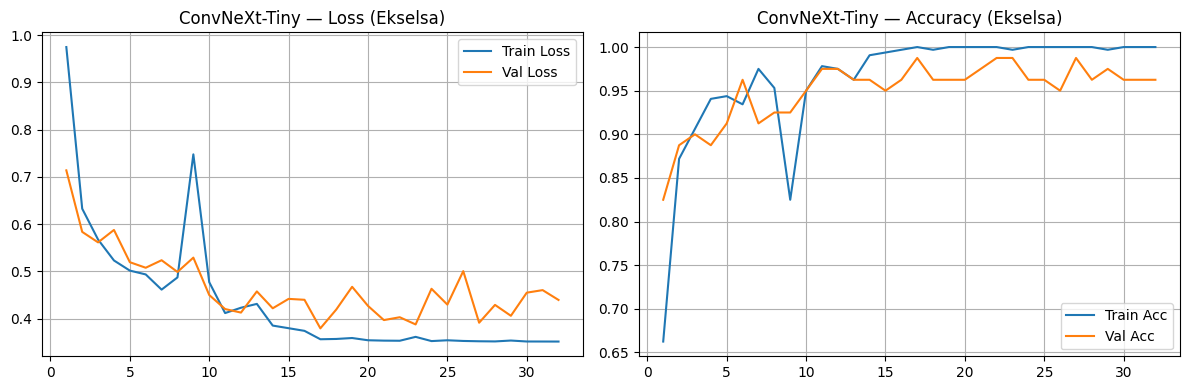


--- Training Sangrai: Liberika (Fold 5) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Liberika
  MULAI TRAINING: CASCADE Liberika Fold 5 | Output: 4 Kelas | Max Epoch: 100
CASCADE Liberika Fold 5 | Epoch 01/100 | Train Loss: 1.0093 Acc: 64.06% | Val Loss: 0.7628 Acc: 76.25%
CASCADE Liberika Fold 5 | Epoch 05/100 | Train Loss: 0.5387 Acc: 90.62% | Val Loss: 0.5382 Acc: 91.25%
CASCADE Liberika Fold 5 | Epoch 10/100 | Train Loss: 0.4697 Acc: 95.00% | Val Loss: 0.4176 Acc: 97.50%
CASCADE Liberika Fold 5 | Epoch 15/100 | Train Loss: 0.3785 Acc: 99.38% | Val Loss: 0.3632 Acc: 100.00%
CASCADE Liberika Fold 5 | Epoch 20/100 | Train Loss: 0.3904 Acc: 98.75% | Val Loss: 0.3663 Acc: 100.00%
CASCADE Liberika Fold 5 | Epoch 25/100 | Train Loss: 0.3523 Acc: 100.00% | Val Loss: 0.4140 Acc: 97.50%
CASCADE Liberika Fold 5 | Epoch 30/100 | Train Loss: 0.3516 Acc: 100.00% | Val Loss: 0.3808 Acc: 98.75%
CASCADE Liberika Fold 5 | Epoch 35/100 | Train Loss: 0.3610 Acc: 99.69% | Val Loss: 0.4029

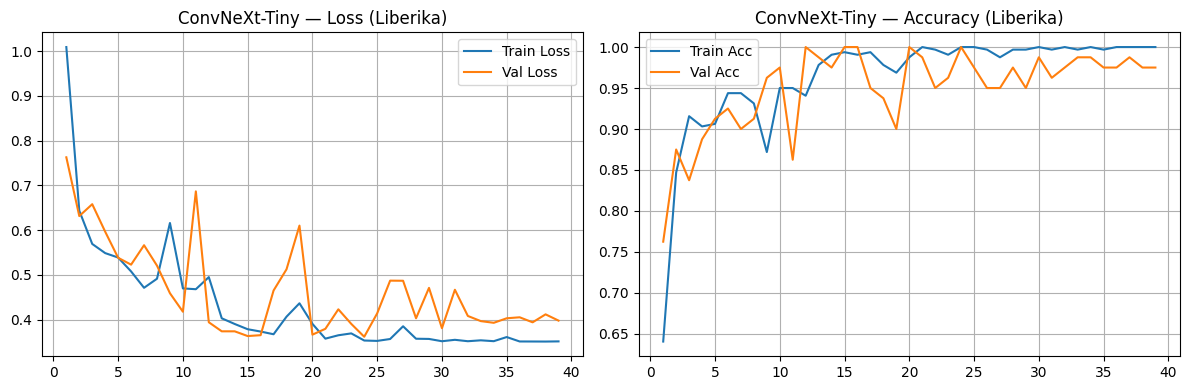


--- Training Sangrai: Robusta (Fold 5) ---

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: Robusta
  MULAI TRAINING: CASCADE Robusta Fold 5 | Output: 4 Kelas | Max Epoch: 100
CASCADE Robusta Fold 5 | Epoch 01/100 | Train Loss: 0.9060 Acc: 68.12% | Val Loss: 0.6828 Acc: 78.75%
CASCADE Robusta Fold 5 | Epoch 05/100 | Train Loss: 0.4980 Acc: 93.12% | Val Loss: 0.4910 Acc: 92.50%
CASCADE Robusta Fold 5 | Epoch 10/100 | Train Loss: 0.5033 Acc: 94.06% | Val Loss: 0.5994 Acc: 88.75%
CASCADE Robusta Fold 5 | Epoch 15/100 | Train Loss: 0.3709 Acc: 99.38% | Val Loss: 0.4272 Acc: 93.75%
CASCADE Robusta Fold 5 | Epoch 20/100 | Train Loss: 0.3568 Acc: 100.00% | Val Loss: 0.3875 Acc: 97.50%
CASCADE Robusta Fold 5 | Epoch 25/100 | Train Loss: 0.3516 Acc: 100.00% | Val Loss: 0.3503 Acc: 100.00%
CASCADE Robusta Fold 5 | Epoch 30/100 | Train Loss: 0.3524 Acc: 100.00% | Val Loss: 0.3569 Acc: 100.00%
CASCADE Robusta Fold 5 | Epoch 35/100 | Train Loss: 0.3509 Acc: 100.00% | Val Loss: 0.3655 Acc: 98.

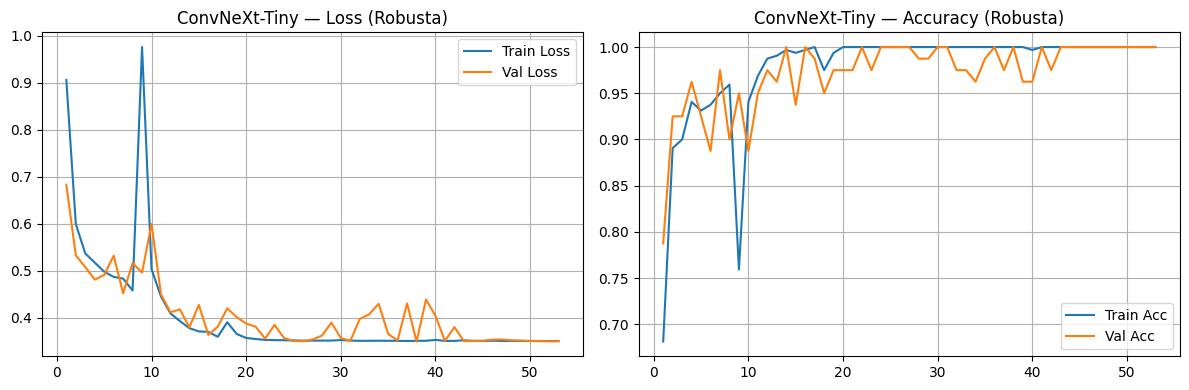


[EVALUASI CASCADE FOLD 5] Memulai evaluasi berantai 16 kelas...
[EVALUASI CASCADE FOLD 5] Selesai!
  Akurasi     : 94.38%
  F1 Macro    : 94.34%
  Precision M : 94.78%
  Recall M    : 94.38%

[SAVED] Ringkasan Stage 1 CSV -> /kaggle/working/reports/Cascade_Jenis_Summary.csv


In [6]:
# --- CASCADE 5-FOLD CROSS VALIDATION (100 EPOCHS) ---
# Pipeline Murni: Stage 1 Jenis -> Stage 2 Sangrai per Jenis -> Evaluasi Berantai 16 Kelas

train_tf, val_tf = get_transforms(img_size=224)

cascade_kfold_metrics = []
oof_casc_targets = []
oof_casc_preds = []
stage1_summary = []

for fold_num in range(1, 6):
    fold_train_root = os.path.join(TARGET_SPLIT2_DIR, f'fold_{fold_num}', 'train')
    fold_val_root   = os.path.join(TARGET_SPLIT2_DIR, f'fold_{fold_num}', 'val')

    print(f'\n{"="*60}')
    print(f'         CASCADE FOLD {fold_num} (100 EPOCHS)')
    print(f'{"="*60}')

    # =========================================================================
    # [STAGE 1] TRAINING MODEL JENIS (4 KELAS)
    # =========================================================================
    print('\n[STAGE 1] Training Model Jenis (4 Spesies)...')

    ds_j_train = datasets.ImageFolder(fold_train_root, transform=train_tf)
    ds_j_val   = datasets.ImageFolder(fold_val_root,   transform=val_tf)

    loader_j_tr = DataLoader(ds_j_train, batch_size=32, shuffle=True,  num_workers=0)
    loader_j_va = DataLoader(ds_j_val,   batch_size=32, shuffle=False, num_workers=0)

    m_j_path = os.path.join(MODELS_DIR, f'ConvNeXt_Jenis_Fold{fold_num}.pth')

    history_j, jenis_best_acc = train_kfold_model(
        train_loader=loader_j_tr,
        val_loader=loader_j_va,
        num_classes=4,
        save_name=m_j_path,
        label_info=f'CASCADE Jenis Fold {fold_num}',
        target_name='Jenis',
        num_epochs=100,
        warmup_epochs=8,
        patience=15
    )

    stage1_summary.append({
        'Fold': f'Fold {fold_num}',
        'Jenis Accuracy (%)': round(jenis_best_acc * 100, 2)
    })

    print(f'\n[INFO] Best Validation Accuracy Jenis Fold {fold_num}: {jenis_best_acc * 100:.2f}%')
    print('>>> MELANJUTKAN TRAINING STAGE 2 (4 MODEL SANGRAI) <<<\n')

    # =========================================================================
    # [STAGE 2] TRAINING MODEL SANGRAI PER JENIS (4 KELAS x 4 SPESIES)
    # =========================================================================
    print(f'[STAGE 2] Training 4 Model Sangrai untuk Fold {fold_num}...')
    m_roast_paths = {}

    for j_name in SPECIES_NAMES:
        print(f'\n--- Training Sangrai: {j_name} (Fold {fold_num}) ---')
        j_tr_path = os.path.join(fold_train_root, j_name)
        j_va_path = os.path.join(fold_val_root,   j_name)

        ds_r_tr = datasets.ImageFolder(j_tr_path, transform=train_tf)
        ds_r_va = datasets.ImageFolder(j_va_path, transform=val_tf)

        loader_r_tr = DataLoader(ds_r_tr, batch_size=32, shuffle=True,  num_workers=0)
        loader_r_va = DataLoader(ds_r_va, batch_size=32, shuffle=False, num_workers=0)

        m_r_path = os.path.join(MODELS_DIR, f'ConvNeXt_{j_name}_Fold{fold_num}.pth')
        m_roast_paths[j_name] = m_r_path

        train_kfold_model(
            train_loader=loader_r_tr,
            val_loader=loader_r_va,
            num_classes=4,
            save_name=m_r_path,
            label_info=f'CASCADE {j_name} Fold {fold_num}',
            target_name=j_name,
            num_epochs=100,
            warmup_epochs=8,
            patience=15
        )

    # =========================================================================
    # [EVALUASI BERANTAI CASCADE 16 KELAS]
    # Input -> Prediksi Jenis -> Routing ke Model Sangrai -> Gabung 16 Kelas
    # =========================================================================
    print(f'\n[EVALUASI CASCADE FOLD {fold_num}] Memulai evaluasi berantai 16 kelas...')
    m_j = build_convnext(num_classes=4).to(device)
    m_j.load_state_dict(torch.load(m_j_path, map_location=device))
    m_j.eval()

    m_r = {}
    for j_n in SPECIES_NAMES:
        m = build_convnext(num_classes=4).to(device)
        m.load_state_dict(torch.load(m_roast_paths[j_n], map_location=device))
        m_r[j_n] = m.eval()

    y_t_casc, y_p_casc = [], []
    for j_idx, j_n in enumerate(SPECIES_NAMES):
        for s_idx, s_n in enumerate(ROAST_NAMES):
            sub_val_dir = os.path.join(fold_val_root, j_n, s_n)
            if not os.path.exists(sub_val_dir):
                continue
            expected_flat = (j_idx * 4) + s_idx
            for img_f in os.listdir(sub_val_dir):
                if not img_f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    continue
                img = Image.open(os.path.join(sub_val_dir, img_f)).convert('RGB')
                tensor = val_tf(img).unsqueeze(0).to(device)
                with torch.no_grad():
                    pred_j_idx = torch.argmax(m_j(tensor), 1).item()
                    pred_j_name = SPECIES_NAMES[pred_j_idx]
                    pred_s_idx = torch.argmax(m_r[pred_j_name](tensor), 1).item()
                    pred_flat = (pred_j_idx * 4) + pred_s_idx

                y_t_casc.append(expected_flat)
                y_p_casc.append(pred_flat)

    c_acc  = accuracy_score(y_t_casc, y_p_casc)
    c_prec = precision_score(y_t_casc, y_p_casc, average='macro', zero_division=0)
    c_rec  = recall_score(y_t_casc, y_p_casc, average='macro', zero_division=0)
    c_f1_m = f1_score(y_t_casc, y_p_casc, average='macro', zero_division=0)
    c_f1_w = f1_score(y_t_casc, y_p_casc, average='weighted', zero_division=0)
    
    print(f'[EVALUASI CASCADE FOLD {fold_num}] Selesai!')
    print(f'  Akurasi     : {c_acc*100:.2f}%')
    print(f'  F1 Macro    : {c_f1_m*100:.2f}%')
    print(f'  Precision M : {c_prec*100:.2f}%')
    print(f'  Recall M    : {c_rec*100:.2f}%')

    oof_casc_targets.extend(y_t_casc)
    oof_casc_preds.extend(y_p_casc)
    cascade_kfold_metrics.append({
        'Fold': f'Fold {fold_num}',
        'Stage 1 Jenis Acc (%)': round(jenis_best_acc * 100, 2),
        'Accuracy (%)': round(c_acc * 100, 2),
        'Precision Macro (%)': round(c_prec * 100, 2),
        'Recall Macro (%)': round(c_rec * 100, 2),
        'F1 Macro (%)': round(c_f1_m * 100, 2),
        'F1 Weighted (%)': round(c_f1_w * 100, 2)
    })

# Simpan CSV ringkasan stage 1 ke reports/
df_stage1 = pd.DataFrame(stage1_summary)
stage1_csv_path = os.path.join(REPORTS_DIR, 'Cascade_Jenis_Summary.csv')
df_stage1.to_csv(stage1_csv_path, index=False)
print(f'\n[SAVED] Ringkasan Stage 1 CSV -> {stage1_csv_path}')


## 6. Rekapitulasi Metrik Kinerja CASCADE 5-Fold Cross Validation


In [7]:
# --- TABEL REKAPITULASI HASIL AKHIR CASCADE 5-FOLD ---
df_casc = pd.DataFrame(cascade_kfold_metrics)

mean_row = {'Fold': 'MEAN (μ)'}
std_row  = {'Fold': 'STD (σ)'}

numeric_cols = [c for c in df_casc.columns if c != 'Fold']
for col in numeric_cols:
    mean_row[col] = round(df_casc[col].mean(), 2)
    std_row[col]  = round(df_casc[col].std(), 2)

df_summary_final = pd.concat([df_casc, pd.DataFrame([mean_row, std_row])], ignore_index=True)

print("\n" + "="*85)
print("             REKAPITULASI RESMI METRIK CASCADE 5-FOLD CROSS VALIDATION")
print("="*85)
print(df_summary_final.to_string(index=False))
print("="*85 + "\n")

# Simpan tabel metrik ke CSV
casc_csv_path = os.path.join(REPORTS_DIR, 'Cascade_KFold_Metrics_Summary.csv')
df_summary_final.to_csv(casc_csv_path, index=False)
print(f"[SAVED] Tabel Metrik CASCADE 5-Fold disimpan di: {casc_csv_path}")



             REKAPITULASI RESMI METRIK CASCADE 5-FOLD CROSS VALIDATION
    Fold  Stage 1 Jenis Acc (%)  Accuracy (%)  Precision Macro (%)  Recall Macro (%)  F1 Macro (%)  F1 Weighted (%)
  Fold 1                  95.94         95.31                95.45             95.31         95.32            95.32
  Fold 2                  94.69         93.75                94.37             93.75         93.60            93.60
  Fold 3                  95.00         94.06                94.98             94.06         93.86            93.86
  Fold 4                  94.69         94.06                94.25             94.06         93.91            93.91
  Fold 5                  95.00         94.38                94.78             94.38         94.34            94.34
MEAN (μ)                  95.06         94.31                94.77             94.31         94.21            94.21
 STD (σ)                   0.51          0.60                 0.48              0.60          0.68             0.68


## 7. Ekspor Berkas Model (.pth) dan Laporan Hasil Pelatihan ke ZIP


[SAVED] Confusion Matrix CSV -> /kaggle/working/reports/KFold_ConfusionMatrix_OOF_CASCADE_Tuned.csv


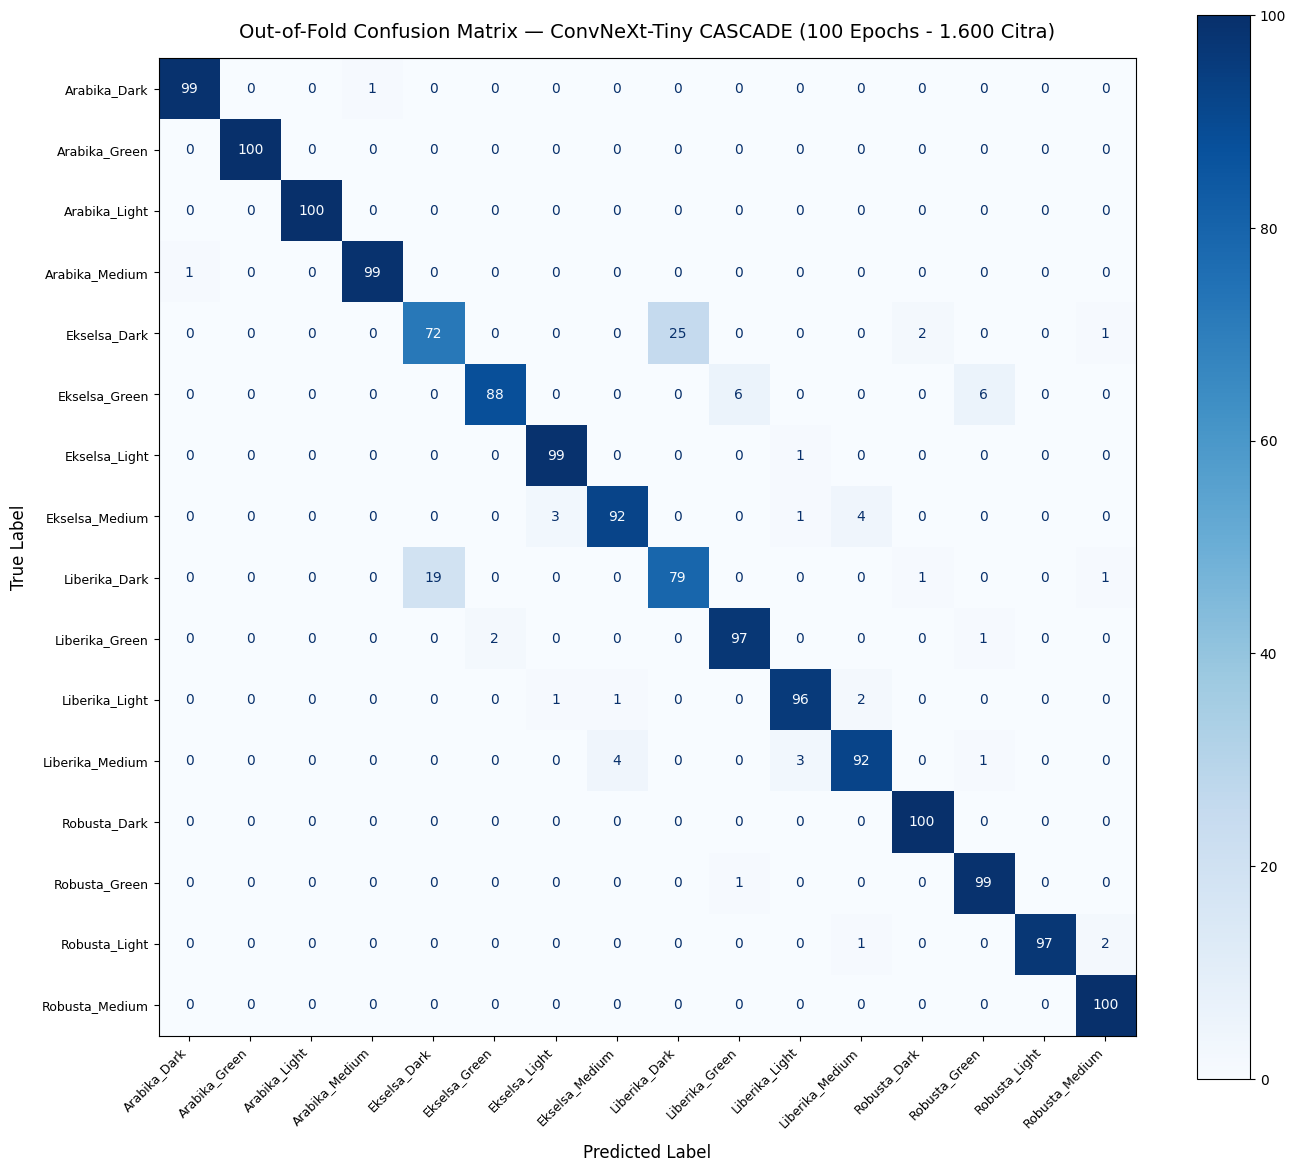

[SAVED] Confusion Matrix Gambar PNG -> /kaggle/working/reports/KFold_ConfusionMatrix_OOF_CASCADE_Tuned.png
[SAVED] Classification Report CSV -> /kaggle/working/reports/KFold_ClassificationReport_OOF_CASCADE_Tuned.csv


In [8]:
# --- CONFUSION MATRIX OUT-OF-FOLD (1.600 CITRA) & CLASSIFICATION REPORT ---
CLASS_NAMES_16 = [f"{j}_{s}" for j in SPECIES_NAMES for s in ROAST_NAMES]
cm_oof = confusion_matrix(oof_casc_targets, oof_casc_preds)

# 1. Simpan CSV Confusion Matrix
df_cm = pd.DataFrame(cm_oof, index=CLASS_NAMES_16, columns=CLASS_NAMES_16)
df_cm.index.name = "True_Class"
cm_csv_path = os.path.join(REPORTS_DIR, "KFold_ConfusionMatrix_OOF_CASCADE_Tuned.csv")
df_cm.to_csv(cm_csv_path)
print(f"[SAVED] Confusion Matrix CSV -> {cm_csv_path}")

# 2. Plot dan Simpan Heatmap Gambar PNG (300 DPI)
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_oof, display_labels=CLASS_NAMES_16)
disp.plot(cmap="Blues", ax=ax, xticks_rotation=45, values_format="d", colorbar=True)
plt.title("Out-of-Fold Confusion Matrix — ConvNeXt-Tiny CASCADE (100 Epochs - 1.600 Citra)", fontsize=14, pad=15)
plt.xlabel("Predicted Label", fontsize=12, labelpad=10)
plt.ylabel("True Label", fontsize=12, labelpad=10)
plt.xticks(fontsize=9, ha="right")
plt.yticks(fontsize=9)
plt.tight_layout()
cm_png_path = os.path.join(REPORTS_DIR, "KFold_ConfusionMatrix_OOF_CASCADE_Tuned.png")
plt.savefig(cm_png_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Confusion Matrix Gambar PNG -> {cm_png_path}")

# 3. Simpan Classification Report OOF CSV
report_dict = classification_report(oof_casc_targets, oof_casc_preds, target_names=CLASS_NAMES_16, output_dict=True)
df_report = pd.DataFrame(report_dict).T
df_report.index.name = "Class"
report_csv_path = os.path.join(REPORTS_DIR, "KFold_ClassificationReport_OOF_CASCADE_Tuned.csv")
df_report.to_csv(report_csv_path, float_format="%.4f")
print(f"[SAVED] Classification Report CSV -> {report_csv_path}")


In [9]:
# --- EKSPOR ZIP HASIL TRAINING CASCADE ---
output_zip = '/kaggle/working/Hasil_Training_CASCADE_100Epochs'
shutil.make_archive(output_zip, 'zip', '/kaggle/working')
print(f'\n[SUCCESS] Semua model (.pth) dan laporan tersimpan di: {output_zip}.zip')



[SUCCESS] Semua model (.pth) dan laporan tersimpan di: /kaggle/working/Hasil_Training_CASCADE_100Epochs.zip
